# 14 · A boundary can supply information or remove it

Enumerate every possible cut of each ring and retain a contiguous window. The open-window experiment has two known prototypes and an unknown cut. Compare each window against all cuts of the opposite prototype. A collision means the chosen observable cannot decide the class uniquely for that window.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.core import power, bispectrum
from observables.patterns import homometric
from observables.stage3 import (tile_library, render, tile_q, cyclic_statistics, matrix_profile,
                                crop_census, orbit, FAMILIES, CONDITIONS, METHODS, run)
OUT = ROOT/'results'/'stage3'
OUT.mkdir(exist_ok=True, parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
a, b = homometric()

## Define the overlap
For an observed window of length $L$, the open pair moment averages over $L-r$ products. The open triple moment at lags $(r,s)$ averages over $L-\max(r,s)$ products. There is no wrap within the window. We use binary occupancy as an exact control. No noise, fitting or estimated cut distribution enters this census.

method,exact window,open pair,open triple
length,,,
4,20,22,22
6,8,15,15
8,0,0,0
10,0,0,0
12,0,0,0


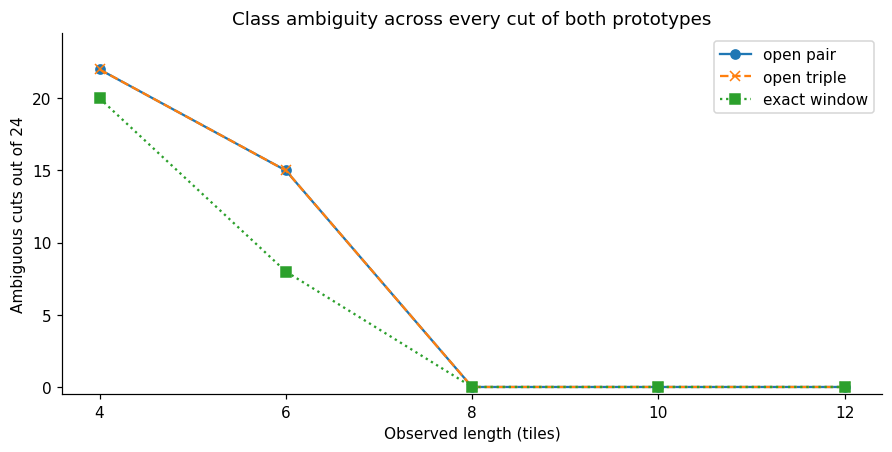

In [3]:
census=crop_census()
census.to_csv(OUT/'crop_census.csv',index=False)
counts=census.groupby(['length','method']).collision.sum().unstack()
display(counts)
fig,ax=plt.subplots(figsize=(8,4))
for method,style in [('open pair','o-'),('open triple','x--'),('exact window','s:')]:
    ax.plot(counts.index,counts[method],style,label=method)
ax.set(xlabel='Observed length (tiles)',ylabel='Ambiguous cuts out of 24',
       title='Class ambiguity across every cut of both prototypes',xticks=counts.index,ylim=(-.5,24.5))
ax.legend();show('14_crop_ambiguity')
assert counts.loc[4,'exact window']==20
assert counts.loc[6,'open pair']==15
assert not counts.loc[8:].to_numpy().any()

## Why can the open pair distinguish a cyclic collision?
At full length, all 24 cuts distinguish the two classes using open pair moments, although their cyclic pair profiles are identical. The open calculation selects which pairs cross the cut and excludes them. This converts the boundary into additional information. It is also a loss of translation invariance. The reference gallery here explicitly enumerates the possible cuts.

In [5]:
from observables.stage3 import open_statistics
x=orbit(a)[0];y=orbit(a)[2]
table=pd.DataFrame({'lag':np.arange(len(x)),
                    'cyclic':cyclic_statistics(x)[0],
                    'open · cut 0':open_statistics(x)[0],
                    'open · cut 2':open_statistics(y)[0],
                    'open products':len(x)-np.arange(len(x))})
display(table.round(3))

,lag,cyclic,open · cut 0,open · cut 2,open products
0,0,0.333,0.333,0.333,12
1,1,0.083,0.091,0.091,11
2,2,0.083,0.100,0.100,10
3,3,0.083,0.111,0.111,9
4,4,0.083,0.125,0.125,8
5,5,0.083,0.143,0.143,7
6,6,0.167,0.167,0.167,6
7,7,0.083,0.000,0.000,5
8,8,0.083,0.000,0.000,4
9,9,0.083,0.000,0.000,3


## What cropping makes unrecoverable
At six tiles, eight cuts have an exact match in the opposite class. Even a lossless representation of the observed window is ambiguous there. The pair and triple profiles each have 15 ambiguous cuts at that length. At eight tiles all tested cuts are distinguishable. These counts apply to the exact pair and all its cyclic cuts. They are not noise tolerance estimates. At the largest lags the estimate can contain a single product, which makes stability under noise a separate question.